
========== DATASET LOADED ==========

   Destination Port  Flow Duration  Total Fwd Packets  Total Backward Packets  \
0             54865              3                  2                       0   
1             55054            109                  1                       1   
2             55055             52                  1                       1   
3             46236             34                  1                       1   
4             54863              3                  2                       0   

   Total Length of Fwd Packets  Total Length of Bwd Packets  \
0                           12                            0   
1                            6                            6   
2                            6                            6   
3                            6                            6   
4                           12                            0   

   Fwd Packet Length Max  Fwd Packet Length Min  Fwd Packet Length Mean  \
0                   

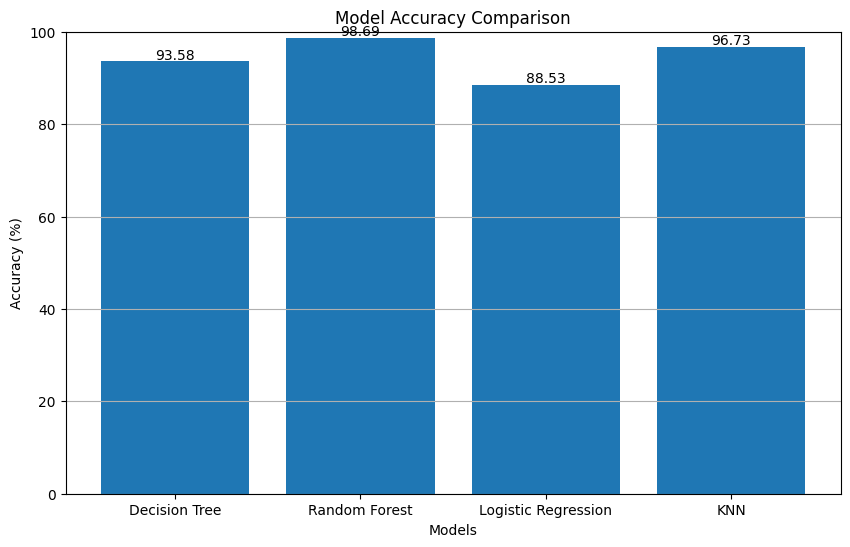

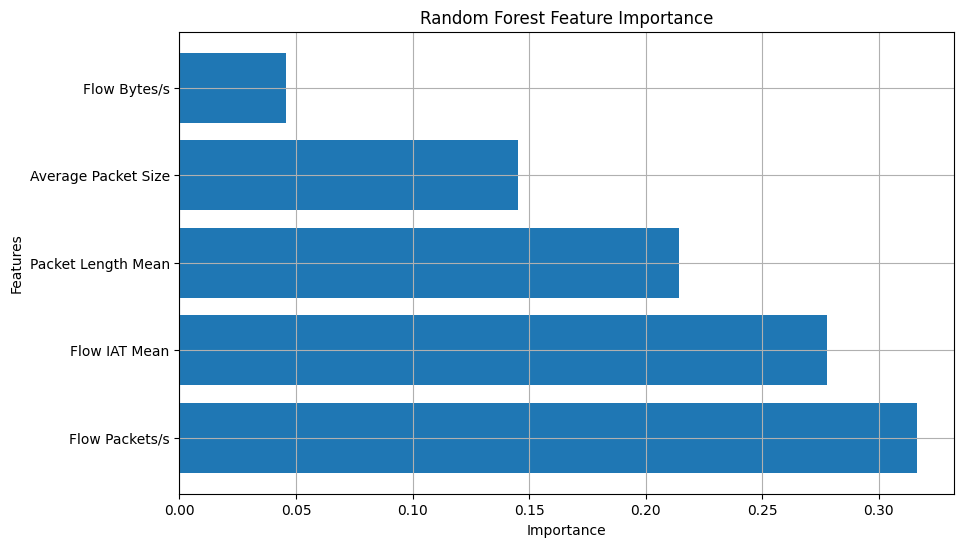

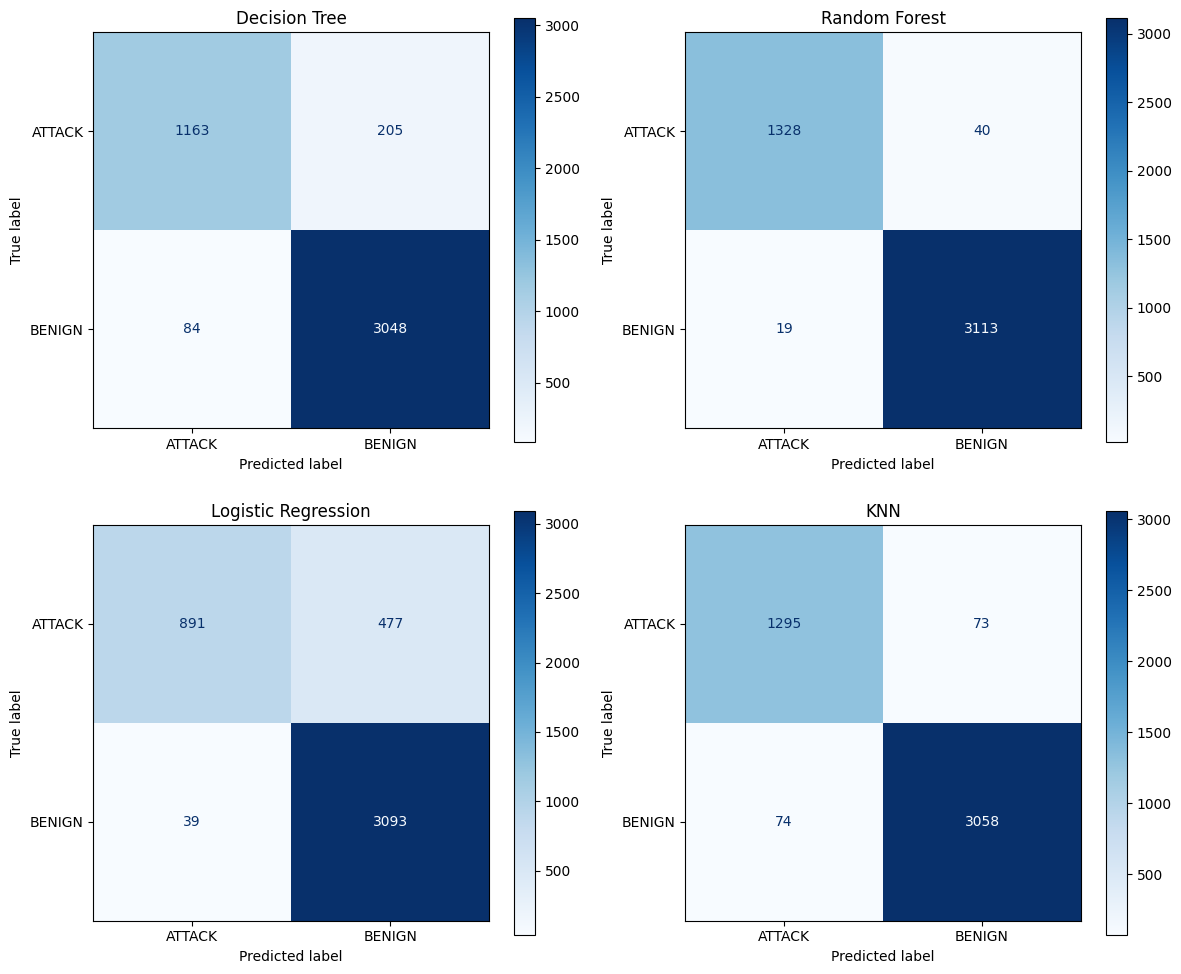


========== PERFORMANCE COMPARISON ==========

                 Model   Accuracy  Precision     Recall   F1-Score
0        Decision Tree  93.577778  93.698125  97.318008  95.473767
1        Random Forest  98.688889  98.731367  99.393359  99.061257
2  Logistic Regression  88.533333  86.638655  98.754789  92.300806
3                  KNN  96.733333  97.668477  97.637292  97.652882


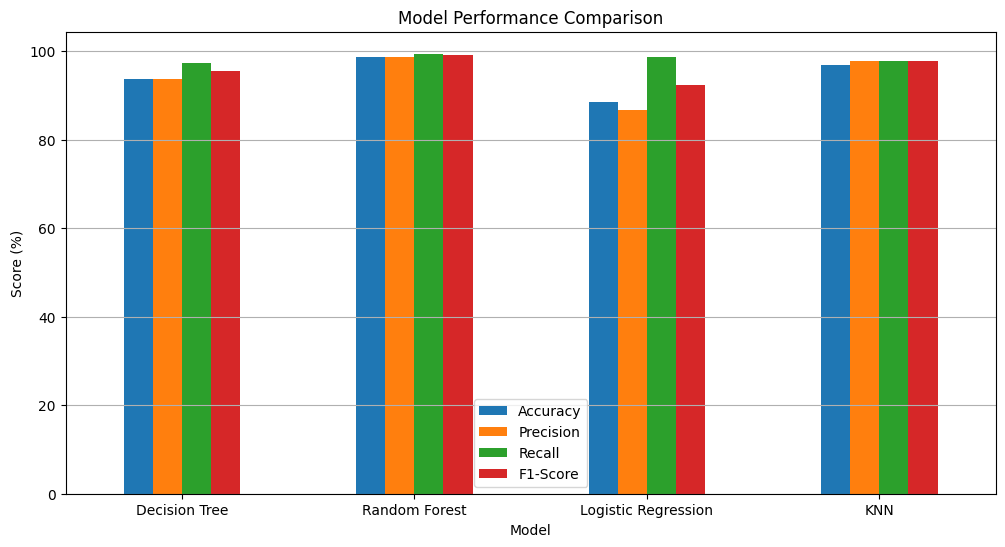

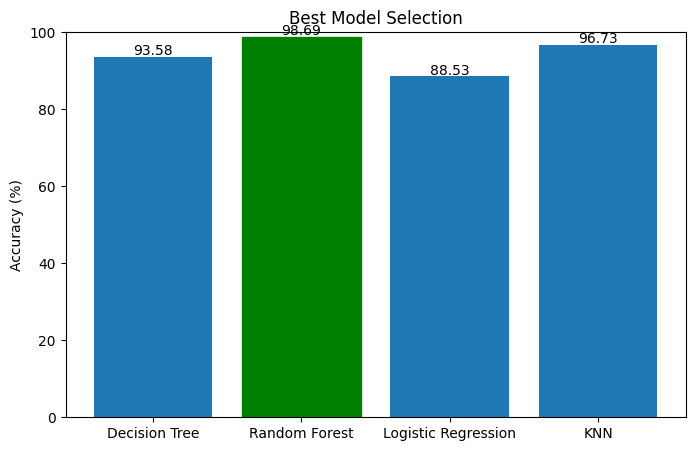


BEST MODEL SELECTED : Random Forest
ACCURACY : 98.69 %


In [ ]:

# THREAT CLASSIFICATION USING MULTIPLE MODELS
# WITH VISUALIZATION
# =========================================

# =========================================
# IMPORT LIBRARIES
# =========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# =========================================
# LOAD DATASET
# =========================================

file_path = r"C:\Users\acer\OneDrive\Desktop\Threat_Dataset_15K.xlsx"

df = pd.read_excel(file_path)

print("\n========== DATASET LOADED ==========\n")

print(df.head())

# =========================================
# HANDLE MISSING VALUES
# =========================================

df.replace([np.inf, -np.inf], np.nan, inplace=True)

df.fillna(0, inplace=True)

print("\n========== MISSING VALUES REMOVED ==========\n")

# =========================================
# CREATE THREAT LABELS
# =========================================

df['Label'] = np.where(
    
    (
        (df['Flow Duration'] > df['Flow Duration'].quantile(0.60)) &
        (df['Total Fwd Packets'] > df['Total Fwd Packets'].median())
    ),
    
    'ATTACK',
    
    'BENIGN'
)
print("\n========== LABEL CREATED ==========\n")

print(df['Label'].value_counts())

# =========================================
# SELECT FEATURES
# =========================================

X = df[[
    
    'Flow Packets/s',
    'Flow IAT Mean',
    'Packet Length Mean',
    'Average Packet Size',
    'Flow Bytes/s'
]]

y = df['Label']

# =========================================
# LABEL ENCODING
# =========================================

le = LabelEncoder()

y = le.fit_transform(y)

# =========================================
# FEATURE SCALING
# =========================================

scaler = StandardScaler()

X = scaler.fit_transform(X)

# =========================================
# SPLIT DATASET
# =========================================

X_train, X_test, y_train, y_test = train_test_split(
    
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("\n========== DATA SPLIT COMPLETED ==========\n")

# =========================================
# DECISION TREE MODEL
# =========================================

dt = DecisionTreeClassifier(
    
    max_depth=3,
    random_state=42
)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

dt_acc = accuracy_score(y_test, dt_pred)

# =========================================
# RANDOM FOREST MODEL
# =========================================

rf = RandomForestClassifier(
    
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

rf_acc = accuracy_score(y_test, rf_pred)

# =========================================
# LOGISTIC REGRESSION MODEL
# =========================================

lr = LogisticRegression(
    
    max_iter=1000
)

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)

lr_acc = accuracy_score(y_test, lr_pred)

# =========================================
# KNN MODEL
# =========================================

knn = KNeighborsClassifier(
    
    n_neighbors=5
)

knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)

knn_acc = accuracy_score(y_test, knn_pred)

# =========================================
# DISPLAY MODEL ACCURACY
# =========================================

print("\n========== MODEL COMPARISON ==========\n")

print("Decision Tree Accuracy :", round(dt_acc * 100, 2), "%")

print("Random Forest Accuracy :", round(rf_acc * 100, 2), "%")

print("Logistic Regression Accuracy :", round(lr_acc * 100, 2), "%")

print("KNN Accuracy :", round(knn_acc * 100, 2), "%")

# =========================================
# MODEL COMPARISON TABLE
# =========================================

comparison = pd.DataFrame({

    "Model": [
        
        "Decision Tree",
        "Random Forest",
        "Logistic Regression",
        "KNN"
    ],

    "Accuracy": [
        
        round(dt_acc * 100, 2),
        round(rf_acc * 100, 2),
        round(lr_acc * 100, 2),
        round(knn_acc * 100, 2)
    ]
})

print("\n========== MODEL ACCURACY TABLE ==========\n")

print(comparison)

# =========================================
# BEST MODEL
# =========================================

accuracies = {
    
    "Decision Tree": dt_acc,
    "Random Forest": rf_acc,
    "Logistic Regression": lr_acc,
    "KNN": knn_acc
}

best_model = max(accuracies, key=accuracies.get)

print("\n===================================")

print("BEST MODEL :", best_model)

print("HIGHEST ACCURACY :", round(accuracies[best_model] * 100, 2), "%")

print("===================================")

# =========================================
# CLASSIFICATION REPORTS
# =========================================

print("\n========== DECISION TREE REPORT ==========\n")

print(classification_report(y_test, dt_pred))

print("\n========== RANDOM FOREST REPORT ==========\n")

print(classification_report(y_test, rf_pred))

print("\n========== LOGISTIC REGRESSION REPORT ==========\n")

print(classification_report(y_test, lr_pred))

print("\n========== KNN REPORT ==========\n")

print(classification_report(y_test, knn_pred))

# =========================================
# MODEL ACCURACY VISUALIZATION
# =========================================

models = [
    
    "Decision Tree",
    "Random Forest",
    "Logistic Regression",
    "KNN"
]

accuracy_values = [
    
    dt_acc * 100,
    rf_acc * 100,
    lr_acc * 100,
    knn_acc * 100
]

plt.figure(figsize=(10,6))

bars = plt.bar(models, accuracy_values)

# SHOW ACCURACY VALUES

for bar in bars:
    
    yval = bar.get_height()
    
    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 0.5,
        round(yval,2),
        ha='center'
    )

plt.xlabel("Models")

plt.ylabel("Accuracy (%)")

plt.title("Model Accuracy Comparison")

plt.ylim(0, 100)

plt.grid(axis='y')

plt.show()

# =========================================
# RANDOM FOREST FEATURE IMPORTANCE
# =========================================

importance = rf.feature_importances_

feature_names = [
    
    'Flow Packets/s',
    'Flow IAT Mean',
    'Packet Length Mean',
    'Average Packet Size',
    'Flow Bytes/s'
]

plt.figure(figsize=(10,6))

plt.barh(feature_names, importance)

plt.xlabel("Importance")

plt.ylabel("Features")

plt.title("Random Forest Feature Importance")

plt.grid()

plt.show()

# =========================================
# CONFUSION MATRIX FOR ALL MODELS
# =========================================

models_predictions = {
    
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "Logistic Regression": lr_pred,
    "KNN": knn_pred
}

plt.figure(figsize=(12,10))

plot_number = 1

for model_name, prediction in models_predictions.items():

    plt.subplot(2,2,plot_number)

    cm = confusion_matrix(y_test, prediction)

    disp = ConfusionMatrixDisplay(
        
        confusion_matrix=cm,
        display_labels=le.classes_
    )

    disp.plot(cmap='Blues', ax=plt.gca())

    plt.title(model_name)

    plot_number += 1

plt.tight_layout()

plt.show()

# =========================================
# PRECISION, RECALL, F1-SCORE COMPARISON
# =========================================

from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

metrics_df = pd.DataFrame({

    "Model": [
        "Decision Tree",
        "Random Forest",
        "Logistic Regression",
        "KNN"
    ],

    "Accuracy": [
        dt_acc * 100,
        rf_acc * 100,
        lr_acc * 100,
        knn_acc * 100
    ],

    "Precision": [
        precision_score(y_test, dt_pred) * 100,
        precision_score(y_test, rf_pred) * 100,
        precision_score(y_test, lr_pred) * 100,
        precision_score(y_test, knn_pred) * 100
    ],

    "Recall": [
        recall_score(y_test, dt_pred) * 100,
        recall_score(y_test, rf_pred) * 100,
        recall_score(y_test, lr_pred) * 100,
        recall_score(y_test, knn_pred) * 100
    ],

    "F1-Score": [
        f1_score(y_test, dt_pred) * 100,
        f1_score(y_test, rf_pred) * 100,
        f1_score(y_test, lr_pred) * 100,
        f1_score(y_test, knn_pred) * 100
    ]
})

print("\n========== PERFORMANCE COMPARISON ==========\n")

print(metrics_df)

# =========================================
# PERFORMANCE VISUALIZATION
# =========================================

metrics_df.set_index("Model").plot(
    
    kind='bar',
    figsize=(12,6)
)

plt.ylabel("Score (%)")

plt.title("Model Performance Comparison")

plt.xticks(rotation=0)

plt.grid(axis='y')

plt.show()

# =========================================
# BEST MODEL VISUALIZATION
# =========================================

best_accuracy = max(accuracy_values)

best_index = accuracy_values.index(best_accuracy)

best_model_name = models[best_index]

plt.figure(figsize=(8,5))

bars = plt.bar(models, accuracy_values)

bars[best_index].set_color('green')

plt.title("Best Model Selection")

plt.ylabel("Accuracy (%)")

plt.ylim(0,100)

for bar in bars:

    yval = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        yval + 0.5,
        round(yval,2),
        ha='center'
    )

plt.show()

print("\n====================================")
print("BEST MODEL SELECTED :", best_model_name)
print("ACCURACY :", round(best_accuracy,2), "%")
print("====================================")
plt.show()